# Adding temporal features to KSI prediction

See whether nighttime and weekend crash patterns, along with recent changes in crash counts, could help improve Claire’s model. I used the previous three years of crash history to build these features and compared the results with the baseline for 2023–2025.

## 1. Imports and output folder

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FEI = ROOT / "Fei"
BASELINE = FEI / "local" / "q1_baseline"
assert (BASELINE / "preprocessing/panel.py").exists(), "Prepare the pinned baseline described above."
sys.path.insert(0, str(FEI))
sys.path.insert(0, str(BASELINE))
from data.reader import read_table
from preprocessing.config import SiteConfig, PanelConfig
from preprocessing.crashes import load_crashes
from preprocessing.sites import project_coordinates, build_site_points, assign_sites, summarize_sites
from preprocessing.panel import load_panel
from model.count_models import NegativeBinomialModel
from validation.validate import ValidationConfig, evaluate, poisson_deviance
from temporal_features import temporal_features, FEATURE_GROUPS

OUTPUT = FEI / "outputs" / "ksi_temporal_features"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Baseline commit:", (BASELINE / "SOURCE_COMMIT.txt").read_text().strip())

Baseline commit: a4530f97456a2ee9f425ea92045141ea8fc2683d


## 2. Reuse the baseline panel and site assignment

Rebuild crash assignments with the exact team functions and confirm site centroids agree. Read only the additional raw time column. The date's weekday is used as recorded; clock time is not converted to UTC. This step may take a few minutes.

In [2]:
#have to downlaod data/raw folder
raw_folder = BASELINE / "data" / "raw"
required = [raw_folder / name for name in ("crashes.parquet", "persons.parquet", "nyc_open_data.duckdb")]
missing = [p.name for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing raw cache files: {missing}")
cloud_only = [p.name for p in raw_folder.iterdir()
              if getattr(p.stat(), "st_flags", 0) & 0x40000000]
if cloud_only:
    raise RuntimeError("Download data/raw in Finder first (right-click > Download Now). "
                       f"iCloud-only files: {cloud_only}")

panel, scoring, sites = load_panel()
site_config, panel_config = SiteConfig(), PanelConfig()
crashes = project_coordinates(load_crashes(), site_config)
site_points = build_site_points(crashes, site_config)
rebuilt = summarize_sites(site_points).set_index("site_id").sort_index()
reference = sites.set_index("site_id").sort_index()
assert rebuilt.index.equals(reference.index)
assert np.allclose(rebuilt[["x", "y"]], reference[["x", "y"]])
crashes = assign_sites(crashes, site_points, site_config)
times = read_table("crashes", ["collision_id", "crash_time"])
times["collision_id"] = pd.to_numeric(times.collision_id, errors="raise").astype("int64")
assert times.collision_id.is_unique, "Review raw duplicate IDs before joining."
crashes = crashes.merge(times, on="collision_id", how="left", validate="one_to_one")
print(f"Baseline: {len(sites):,} sites; {len(panel):,} site-years.")
print(f"Crashes outside the fixed site coverage: {crashes.site_id.isna().sum():,}")

Baseline: 89,073 sites; 356,292 site-years.
Crashes outside the fixed site coverage: 18,031


In [3]:
print("Panel years:", sorted(panel["year"].unique()))
print("Raw crash dates:",
      crashes["crash_date"].min(),
      "to",
      crashes["crash_date"].max())

Panel years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Raw crash dates: 2017-01-01 00:00:00 to 2026-06-11 00:00:00


## 3. Build historical features

- Nighttime: 22:00–05:59. Numerator = nighttime crashes; denominator = crashes with valid clock time.
- Weekend: Saturday/Sunday crashes divided by all crashes.
- Recent change: `log(1 + crashes in t−1) − log(1 + mean crashes in t−2 and t−3)`.

Shares use pooled three-year counts. Missing clock times are excluded from the night-share denominator and tracked separately. No-history and no-known-time indicators distinguish an unavailable share from a real zero. These are shares of recorded crashes, not traffic-exposure rates.

In [4]:
features = temporal_features(crashes, sites.site_id, panel_config.first_year, panel_config.last_year)
columns = list(dict.fromkeys(x for group in FEATURE_GROUPS.values() for x in group))
experiment = panel.merge(features[["site_id", "year", "total_lag3", *columns]], on=["site_id", "year"], validate="one_to_one")
assert len(experiment) == len(panel)
assert np.allclose(experiment.total_lag3, experiment.crashes_lag3), "Historical counts differ from baseline."
assert np.isfinite(experiment[columns].to_numpy()).all()
quality = experiment.groupby("year")[["no_history", "night_unavailable", "unknown_time_share_lag3"]].mean()
display(quality)
display(experiment[columns].describe().round(3))
quality.to_csv(OUTPUT / "temporal_feature_quality.csv")

,no_history,night_unavailable,unknown_time_share_lag3
year,,,
2022,0.234572,0.234572,0.0
2023,0.286170,0.286170,0.0
2024,0.301135,0.301135,0.0
2025,0.345885,0.345885,0.0


,night_share_lag3,unknown_time_share_lag3,night_unavailable,no_history,weekend_share_lag3,recent_log_change
count,356292.000,356292.0,356292.000,356292.000,356292.000,356292.000
mean,0.139,0.0,0.292,0.292,0.193,-0.097
std,0.262,0.0,0.455,0.455,0.303,0.505
min,0.000,0.0,0.000,0.000,0.000,-3.773
25%,0.000,0.0,0.000,0.000,0.000,-0.405
50%,0.000,0.0,0.000,0.000,0.000,0.000
75%,0.200,0.0,1.000,1.000,0.333,0.000
max,1.000,0.0,1.000,1.000,1.000,3.219


In [5]:
from temporal_features import select_features

supp_site_config = SiteConfig(build_end="2023-01-01")
supp_panel_config = PanelConfig(last_year=2023)
print("Building supplementary sites using pre-2023 crashes...", flush=True)
supp_panel, _, supp_sites = load_panel(site_config=supp_site_config, config=supp_panel_config)

# Reuse cleaned crash rows and raw clock times already loaded above.
# Drop the old site assignment before applying the new, pre-2023 sites.
supp_crashes = crashes.drop(columns=["site_id"]).copy()
supp_crashes = supp_crashes[supp_crashes.crash_date < pd.Timestamp("2024-01-01")].copy()
supp_points = build_site_points(supp_crashes, supp_site_config)
supp_reference = supp_sites.set_index("site_id").sort_index()
supp_rebuilt = summarize_sites(supp_points).set_index("site_id").sort_index()
assert supp_rebuilt.index.equals(supp_reference.index)
assert np.allclose(supp_rebuilt[["x", "y"]], supp_reference[["x", "y"]])
supp_crashes = assign_sites(supp_crashes, supp_points, supp_site_config)
supp_features = temporal_features(supp_crashes, supp_sites.site_id,
                                  supp_panel_config.first_year, supp_panel_config.last_year)
supp_experiment = supp_panel.merge(
    supp_features[["site_id", "year", "total_lag3", *columns]],
    on=["site_id", "year"], validate="one_to_one")
assert len(supp_experiment) == len(supp_panel)
assert set(supp_experiment.year) == {2022, 2023}
assert np.allclose(supp_experiment.total_lag3, supp_experiment.crashes_lag3)
assert np.isfinite(supp_experiment[columns].to_numpy(dtype=float)).all()
print(f"2023 supplement: {len(supp_sites):,} sites; train = 2022; test = 2023.")

experiments = {2023: supp_experiment, 2024: experiment, 2025: experiment}
TEST_YEARS = (2023, 2024, 2025)


Building supplementary sites using pre-2023 crashes...


2023 supplement: 86,167 sites; train = 2022; test = 2023.


## 4. Test feature groups separately and together

Reuse identical training/test rows. First test each feature group, then all groups. Constant features and identical feature columns are omitted using training rows only. For example, when every recorded crash has a valid time, night_unavailable and no_history are identical; only one is retained. Omitted features and reasons are recorded. This check does not resolve every possible form of linear dependence. Top-k capture is the fraction of test-year KSI in the top-ranked sites; deviance scores all sites. Calibration compares observed versus predicted counts.

Add `Baseline + no_history` as a control. Compare each temporal model with this control to separate the value of temporal patterns from the no-history indicator.

In [6]:
from temporal_features import select_features

HISTORY = [f"log1p_{c}_lag3" for c in ["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal", "ped_injured", "cyc_injured"]]
CONTROL = "Baseline + no_history"
specs = {"Baseline": HISTORY, CONTROL: HISTORY + ["no_history"]}
specs.update({"+ " + name: list(dict.fromkeys(HISTORY + group)) for name, group in FEATURE_GROUPS.items()})
specs["+ All temporal"] = HISTORY + columns
results, calibrations, omitted = [], [], []
for year in TEST_YEARS:
    fold = experiments[year]
    train = fold[fold.year < year]
    assert train.year.max() < year
    site_build_end = "2023-01-01" if year == 2023 else "2024-01-01"
    for name, requested in specs.items():
        used, dropped = select_features(train, requested)
        omitted.append({"year": year, "model": name, "omitted_features": "; ".join(f"{f}: {reason}" for f, reason in dropped.items())})
        print("Fitting", year, name, "| omitted:", dropped, flush=True)
        config = ValidationConfig(test_years=(year,))
        capture, calibration, predictions = evaluate(lambda: NegativeBinomialModel(used), fold, config)
        results.append({"year": year, "model": name,
                        "site_build_end": site_build_end,
                        "training_years": ",".join(map(str, sorted(train.year.unique()))),
                        "n_sites": fold.site_id.nunique(),
                        "top_100": capture.set_index("k").loc[100, "capture"],
                        "top_1000": capture.set_index("k").loc[1000, "capture"],
                        "deviance": poisson_deviance(predictions.ksi, predictions.pred),
                        "observed_predicted_ratio": predictions.ksi.sum() / predictions.pred.sum()})
        calibrations.append(calibration.assign(model=name))
        print("Completed", year, name)
results = pd.DataFrame(results)
calibration = pd.concat(calibrations, ignore_index=True)
results.to_csv(OUTPUT / "model_comparison_by_year.csv", index=False)
calibration.to_csv(OUTPUT / "calibration_by_year.csv", index=False)
pd.DataFrame(omitted).to_csv(OUTPUT / "omitted_features.csv", index=False)
display(results.round(4))

Fitting 2023 Baseline | omitted: {}


Completed 2023 Baseline
Fitting 2023 Baseline + no_history | omitted: {}


Completed 2023 Baseline + no_history
Fitting 2023 + Nighttime | omitted: {'unknown_time_share_lag3': 'constant in training data', 'no_history': 'identical to night_unavailable in training data'}


Completed 2023 + Nighttime
Fitting 2023 + Weekend | omitted: {}


Completed 2023 + Weekend
Fitting 2023 + Recent change | omitted: {}


Completed 2023 + Recent change
Fitting 2023 + All temporal | omitted: {'unknown_time_share_lag3': 'constant in training data', 'no_history': 'identical to night_unavailable in training data'}


... (10 outputs left out)

Completed 2025 + Weekend
Fitting 2025 + Recent change | omitted: {}


Completed 2025 + Recent change
Fitting 2025 + All temporal | omitted: {'unknown_time_share_lag3': 'constant in training data', 'no_history': 'identical to night_unavailable in training data'}


Completed 2025 + All temporal


,year,model,site_build_end,training_years,n_sites,top_100,top_1000,deviance,observed_predicted_ratio
0,2023,Baseline,2023-01-01,2022,86167,0.0250,0.1556,0.1711,1.2694
1,2023,Baseline + no_history,2023-01-01,2022,86167,0.0250,0.1556,0.1711,1.2707
2,2023,+ Nighttime,2023-01-01,2022,86167,0.0250,0.1560,0.1711,1.2667
3,2023,+ Weekend,2023-01-01,2022,86167,0.0246,0.1563,0.1711,1.2703
4,2023,+ Recent change,2023-01-01,2022,86167,0.0257,0.1545,0.1705,1.2252
5,2023,+ All temporal,2023-01-01,2022,86167,0.0257,0.1556,0.1705,1.2233
6,2024,Baseline,2024-01-01,"2022,2023",89073,0.0251,0.1527,0.1643,0.9815
7,2024,Baseline + no_history,2024-01-01,"2022,2023",89073,0.0251,0.1527,0.1638,0.9813
8,2024,+ Nighttime,2024-01-01,"2022,2023",89073,0.0251,0.1519,0.1638,0.9804
9,2024,+ Weekend,2024-01-01,"2022,2023",89073,0.0251,0.1523,0.1638,0.9817


## 5. Compare ranking and count accuracy
Show 2023, 2024 and 2025 separately. The 2023 fold has a different site set and only one training outcome year; do not interpret cross-year score differences as changes in model quality alone. A gain in one year alone is not evidence of a stable improvement.

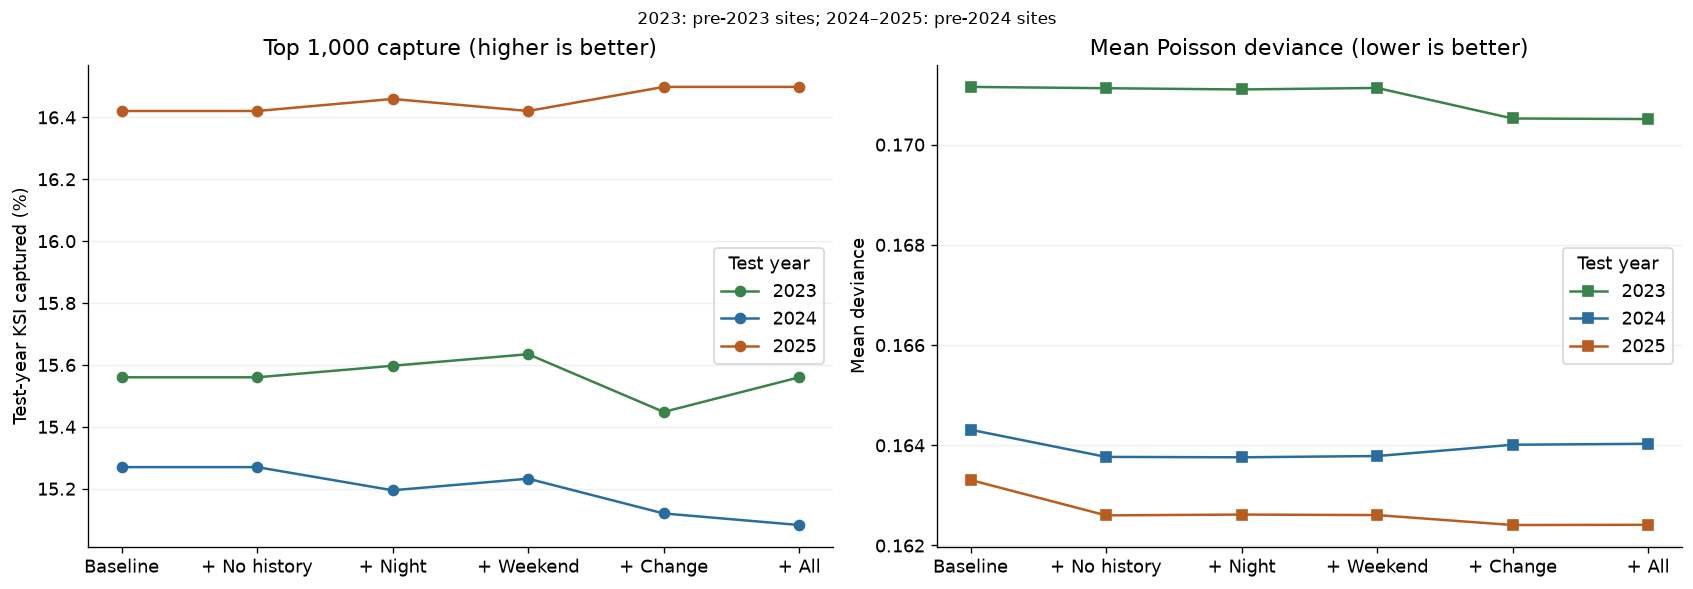

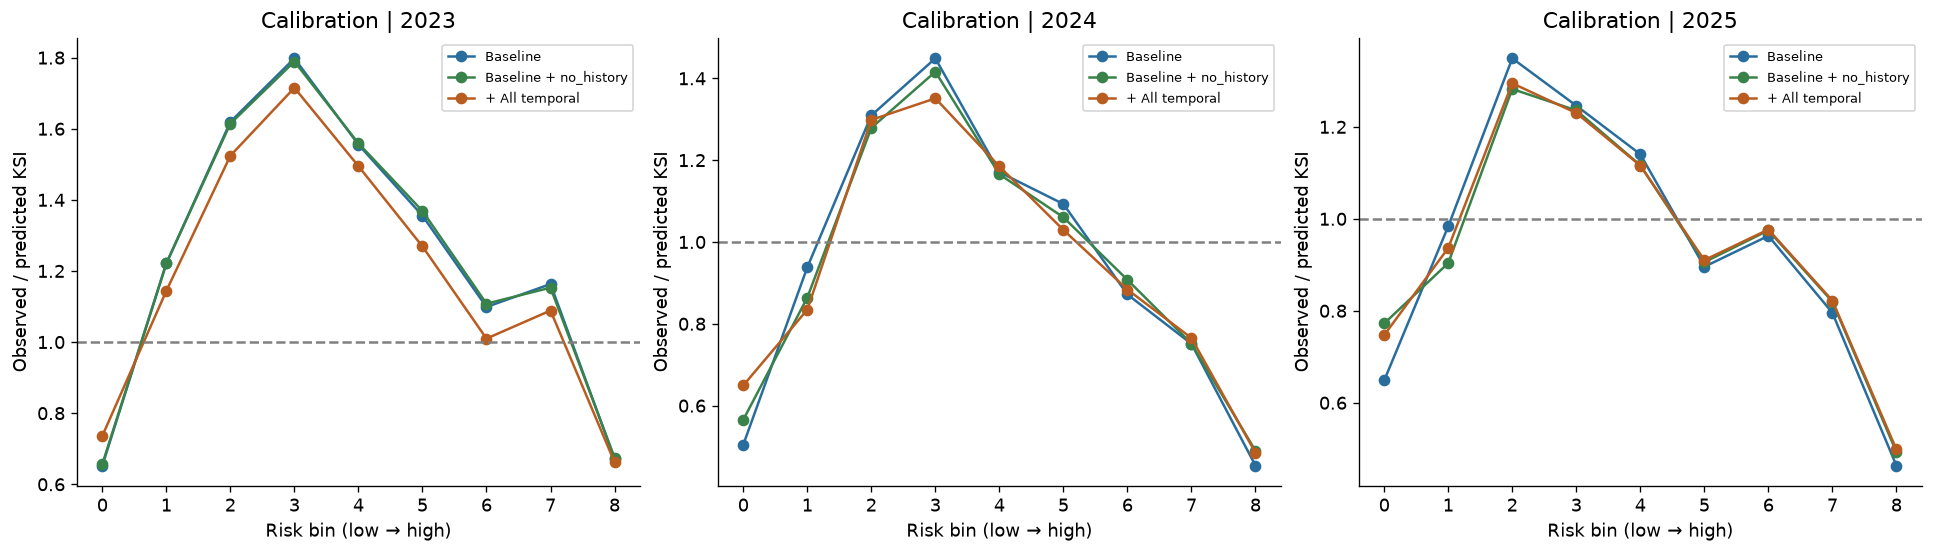

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout="constrained")
for year, color in [(2023, "#39834B"), (2024, "#286D9E"), (2025, "#B85C20")]:
    d = results[results.year == year].set_index("model").reindex(specs)
    axes[0].plot(range(len(d)), 100*d.top_1000, marker="o", color=color, label=str(year))
    axes[1].plot(range(len(d)), d.deviance, marker="s", color=color, label=str(year))
labels = ["Baseline", "+ No history", "+ Night", "+ Weekend", "+ Change", "+ All"]
for ax in axes:
    ax.set_xticks(range(len(labels)), labels)
    ax.legend(title="Test year")
    ax.grid(axis="y", alpha=0.2)
axes[0].set(title="Top 1,000 capture (higher is better)", ylabel="Test-year KSI captured (%)")
axes[1].set(title="Mean Poisson deviance (lower is better)", ylabel="Mean deviance")
fig.suptitle("2023: pre-2023 sites; 2024–2025: pre-2024 sites", fontsize=10)
fig.savefig(OUTPUT / "temporal_model_comparison.png", dpi=180)
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
for ax, year in zip(axes, TEST_YEARS):
    for name, color in [("Baseline", "#286D9E"), (CONTROL, "#39834B"), ("+ All temporal", "#B85C20")]:
        d = calibration[(calibration.test_year == year) & (calibration.model == name)].sort_values("bin")
        ratio = d.obs_total / d.pred_total.replace(0, np.nan)
        ax.plot(range(len(d)), ratio, marker="o", color=color, label=name)
    ax.axhline(1, color="gray", linestyle="--")
    ax.set(title=f"Calibration | {year}", xlabel="Risk bin (low → high)", ylabel="Observed / predicted KSI")
    ax.legend(fontsize=8)
fig.savefig(OUTPUT / "temporal_calibration.png", dpi=180)
plt.show()

## 6. Interpret the comparison

Small differences are exploratory and not a significance test. Night/weekend patterns may reflect traffic exposure, land use or reporting rather than causal risk factors. Sites use pre-2023 crashes for the 2023 test and pre-2024 crashes for the 2024–2025 tests; this evaluates future risk at those known sites, not discovery of entirely new sites. Keep existing KSI-proxy and site-coverage limitations.

In [8]:
comparisons = []
for year in TEST_YEARS:
    d = results[results.year == year].set_index("model")
    for reference in ("Baseline", CONTROL):
        base = d.loc[reference]
        for name in specs:
            if name == reference:
                continue
            row = d.loc[name]
            comparisons.append({
                "year": year, "model": name, "reference": reference,
                "capture_change_pp": 100 * (row.top_1000 - base.top_1000),
                "deviance_change_pct": 100 * (row.deviance / base.deviance - 1)})
comparisons = pd.DataFrame(comparisons)
comparisons.to_csv(OUTPUT / "feature_increment_comparison.csv", index=False)
print("Changes relative to Baseline + no_history:")
display(comparisons[comparisons.reference == CONTROL].round(4))
print("Positive capture change and negative deviance change are improvements.")
print("Compare temporal models with the no-history control within each year; these are not significance tests.")


Changes relative to Baseline + no_history:


,year,model,reference,capture_change_pp,deviance_change_pct
5,2023,Baseline,Baseline + no_history,0.0000,0.0152
6,2023,+ Nighttime,Baseline + no_history,0.0373,-0.0146
7,2023,+ Weekend,Baseline + no_history,0.0746,0.0034
8,2023,+ Recent change,Baseline + no_history,-0.1119,-0.3530
9,2023,+ All temporal,Baseline + no_history,0.0000,-0.3594
15,2024,Baseline,Baseline + no_history,0.0000,0.3311
16,2024,+ Nighttime,Baseline + no_history,-0.0749,-0.0048
17,2024,+ Weekend,Baseline + no_history,-0.0374,0.0107
18,2024,+ Recent change,Baseline + no_history,-0.1497,0.1481
19,2024,+ All temporal,Baseline + no_history,-0.1871,0.1600


Positive capture change and negative deviance change are improvements.
Compare temporal models with the no-history control within each year; these are not significance tests.
